# Etapa II · Fase 2 · Bloque C-3: representación

**Pregunta:** con la mejor normalización de cada modelo, ¿qué representación funciona mejor:
binaria, frecuencia o TF-IDF?

| | |
|---|---|
| **Factor que cambia** | La representación: binaria, frecuencia, TF-IDF |
| **Fijo** | La mejor normalización de C-2 para cada modelo (NB N1, LR N2, SVC N0); unigramas; sin SVD |
| **Experimentos nuevos** | C10--C15 (6) |
| **Reutilizados** | C07 (NB+N1), C02 (LR+N2), C06 (SVC+N0) como celdas TF-IDF |

La celda TF-IDF ya estaba medida en C-2; no se repite. Este notebook lee los resultados
congelados de `experiments.tsv`, no vuelve a entrenar ni toca test.

In [1]:
%matplotlib inline

In [2]:
import os
os.environ.setdefault("MPLCONFIGDIR", "/tmp/mplconfig")
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image

pd.set_option("display.width", 180)
pd.set_option("display.max_colwidth", 90)
print("Raíz:", ROOT)


Raíz: /home/mrangello/Documentos/PracticaML


In [3]:
exp = pd.read_csv(ROOT / "results/etapa2/experiments.tsv", sep="\t",
                   dtype=str, keep_default_na=False)

def dev_macro_f1(row):
    return float(row["dev_metric"].split("macro_f1=")[1].split(";")[0])

def extra_dict(row):
    return dict(part.split("=", 1) for part in row["extra"].split("; "))

def get(exp_id):
    return exp[exp["experiment_id"] == exp_id].iloc[0]


## 1. Los nueve resultados de C-3

In [4]:
cells = [
    ("MultinomialNB", "binaria", "C10"),
    ("MultinomialNB", "frecuencia", "C11"),
    ("MultinomialNB", "TF-IDF", "C07"),
    ("LogisticRegression", "binaria", "C12"),
    ("LogisticRegression", "frecuencia", "C13"),
    ("LogisticRegression", "TF-IDF", "C02"),
    ("SVC", "binaria", "C14"),
    ("SVC", "frecuencia", "C15"),
    ("SVC", "TF-IDF", "C06"),
]
rows = []
for model, representation, exp_id in cells:
    row = get(exp_id)
    rows.append({
        "Modelo": model,
        "Representación": representation,
        "Exp.": exp_id,
        "Dev macro-F1": round(dev_macro_f1(row), 4),
        "CV macro-F1": round(float(row["cv_macro_f1"]), 4),
        "n_features": int(extra_dict(row)["n_features"]),
    })
table = pd.DataFrame(rows)
display(table)

,Modelo,Representación,Exp.,Dev macro-F1,CV macro-F1,n_features
0,MultinomialNB,binaria,C10,0.7049,0.7404,3814
1,MultinomialNB,frecuencia,C11,0.7327,0.7492,3814
2,MultinomialNB,TF-IDF,C07,0.7745,0.7612,3814
3,LogisticRegression,binaria,C12,0.7445,0.7437,3033
4,LogisticRegression,frecuencia,C13,0.7457,0.7326,3033
5,LogisticRegression,TF-IDF,C02,0.7993,0.7675,6689
6,SVC,binaria,C14,0.7466,0.7081,4608
7,SVC,frecuencia,C15,0.6624,0.6532,4608
8,SVC,TF-IDF,C06,0.7742,0.7451,9974


**Cómo leerla:** `Dev macro-F1` es la métrica de selección; `CV macro-F1` es la media de
la validación cruzada en train y ayuda a ver si una diferencia es real. `n_features` es el
tamaño del vocabulario tras `min_df`.

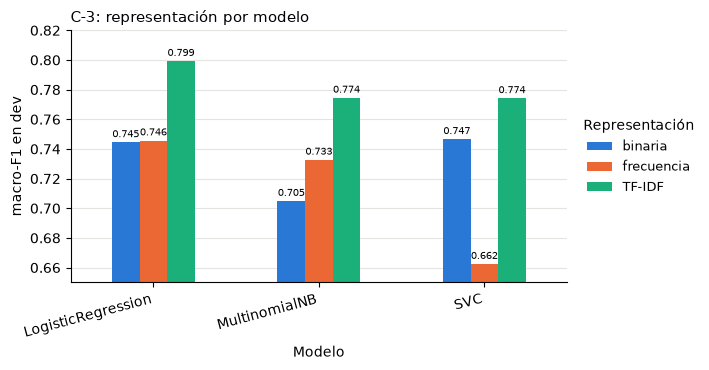

In [5]:
pivot = table.pivot(index="Modelo", columns="Representación",
                     values="Dev macro-F1")[["binaria", "frecuencia", "TF-IDF"]]
ax = pivot.plot(kind="bar", figsize=(7.2, 3.8),
                color=["#2a78d6", "#eb6834", "#1baf7a"])
ax.set_ylim(0.65, 0.82)
ax.set_ylabel("macro-F1 en dev")
ax.set_title("C-3: representación por modelo", loc="left", fontsize=11)
ax.legend(loc="center left", bbox_to_anchor=(1.01, 0.5), frameon=False,
          title="Representación", fontsize=9)
ax.set_xticklabels(pivot.index, rotation=15, ha="right")
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", color="#e5e4e0", lw=0.8)
ax.set_axisbelow(True)
for container in ax.containers:
    ax.bar_label(container, fmt="%.3f", padding=2, fontsize=7)
plt.tight_layout()
plt.show()

## 2. Lectura

- **TF-IDF gana en los tres modelos**: NB 0.7745, LR 0.7993 y SVC 0.7742.
- La representación **binaria** y la de **frecuencia** pierden entre 3 y 9 puntos. El caso
  más claro es SVC con frecuencia: 0.6624 frente a 0.7742 de TF-IDF.
- **NB es el más sensible**: binaria cae a 0.7049; TF-IDF le da 0.7745.
- TF-IDF baja el peso de palabras que aparecen en casi todos los abstracts y sube el de las
  que distinguen un área; con 350 documentos, esa ponderación es la que mejor funciona.
- **Selección para C-4:** se mantiene TF-IDF en los tres modelos (C07, C02, C06), porque es
  la mejor representación en dev para cada uno.

## 3. Registro

Las filas C10--C15 quedaron en `results/etapa2/experiments.tsv` con `block = C-3`. Ninguna
se marcó como `selected`: la selección final se hace por clasificador en la Fase 3 y, en
C-3, la representación que pasa es TF-IDF, ya registrada en C-2.